In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

ModuleNotFoundError: No module named 'pandas'

In [ ]:
myData = pd.read_csv('lung_cancer_dataset_large.csv')
myData

,Age,Smoking_History,Exposure_to_Pollution,Genetic_Predisposition,Chronic_Lung_Disease,Cough_Intensity,Shortness_of_Breath,Chest_Pain,Weight_Loss,Fatigue_Level,...,Radiation_Exposure,Bronchitis_History,Occupation_Risk,Alcohol_Consumption,Diet_Quality,Physical_Activity_Level,Lung_Capacity,Family_History_Cancer,Inflammation_Level,Lung_Cancer_Type
0,78,Current,0.805929,0,0,8,0,3,7.419077,6,...,0.994068,0,Low,0,Poor,8,4.572709,1,0.718452,Adenocarcinoma
1,68,Former,0.259916,0,1,1,2,6,4.967348,3,...,0.760310,0,Medium,2,Poor,5,5.118447,1,0.843894,Squamous Cell Carcinoma
2,54,Current,0.300621,1,0,1,1,9,5.678273,0,...,0.131923,0,Low,2,Good,6,4.799020,1,0.587978,Small Cell Lung Cancer
3,82,Former,0.661154,0,0,2,4,3,5.850399,7,...,0.416859,0,Low,8,Poor,2,4.957877,0,0.495123,Squamous Cell Carcinoma
4,47,Former,0.695585,1,0,4,0,4,5.226715,2,...,0.464967,0,Low,0,Average,6,4.718326,1,0.124804,Adenocarcinoma
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,65,Former,0.973580,1,0,7,1,2,5.100637,4,...,0.405605,1,Low,0,Good,9,4.912563,0,0.708533,Small Cell Lung Cancer
9996,61,Former,0.116754,0,0,6,7,5,4.892936,5,...,0.754477,0,Medium,9,Poor,4,6.292613,1,0.657464,Small Cell Lung Cancer
9997,70,Former,0.486633,1,0,9,1,8,3.486220,9,...,0.289881,0,Low,2,Average,5,1.816306,1,0.093590,Adenocarcinoma
9998,82,Never,0.408488,1,0,3,1,2,5.368940,5,...,0.121289,0,Medium,7,Average,8,3.841013,0,0.151246,Adenocarcinoma


In [ ]:
myData.head()

,Age,Smoking_History,Exposure_to_Pollution,Genetic_Predisposition,Chronic_Lung_Disease,Cough_Intensity,Shortness_of_Breath,Chest_Pain,Weight_Loss,Fatigue_Level,...,Radiation_Exposure,Bronchitis_History,Occupation_Risk,Alcohol_Consumption,Diet_Quality,Physical_Activity_Level,Lung_Capacity,Family_History_Cancer,Inflammation_Level,Lung_Cancer_Type
0,78,Current,0.805929,0,0,8,0,3,7.419077,6,...,0.994068,0,Low,0,Poor,8,4.572709,1,0.718452,Adenocarcinoma
1,68,Former,0.259916,0,1,1,2,6,4.967348,3,...,0.760310,0,Medium,2,Poor,5,5.118447,1,0.843894,Squamous Cell Carcinoma
2,54,Current,0.300621,1,0,1,1,9,5.678273,0,...,0.131923,0,Low,2,Good,6,4.799020,1,0.587978,Small Cell Lung Cancer
3,82,Former,0.661154,0,0,2,4,3,5.850399,7,...,0.416859,0,Low,8,Poor,2,4.957877,0,0.495123,Squamous Cell Carcinoma
4,47,Former,0.695585,1,0,4,0,4,5.226715,2,...,0.464967,0,Low,0,Average,6,4.718326,1,0.124804,Adenocarcinoma


In [ ]:
myData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      10000 non-null  int64  
 1   Smoking_History          10000 non-null  object 
 2   Exposure_to_Pollution    10000 non-null  float64
 3   Genetic_Predisposition   10000 non-null  int64  
 4   Chronic_Lung_Disease     10000 non-null  int64  
 5   Cough_Intensity          10000 non-null  int64  
 6   Shortness_of_Breath      10000 non-null  int64  
 7   Chest_Pain               10000 non-null  int64  
 8   Weight_Loss              10000 non-null  float64
 9   Fatigue_Level            10000 non-null  int64  
 10  Tumor_Size               10000 non-null  float64
 11  Radiation_Exposure       10000 non-null  float64
 12  Bronchitis_History       10000 non-null  int64  
 13  Occupation_Risk          10000 non-null  object 
 14  Alcohol_Consumption    

In [ ]:
myData.describe()

,Age,Exposure_to_Pollution,Genetic_Predisposition,Chronic_Lung_Disease,Cough_Intensity,Shortness_of_Breath,Chest_Pain,Weight_Loss,Fatigue_Level,Tumor_Size,Radiation_Exposure,Bronchitis_History,Alcohol_Consumption,Physical_Activity_Level,Lung_Capacity,Family_History_Cancer,Inflammation_Level
count,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,64.620400,0.507825,0.2909,0.199500,4.436400,4.57190,4.496700,4.975061,4.48570,4.475720,0.501411,0.303700,4.45070,4.510300,4.024194,0.411400,0.497680
std,14.343489,0.287013,0.4542,0.399644,2.870954,2.87737,2.889225,1.999012,2.86161,2.012689,0.288482,0.459878,2.87416,2.868713,1.440697,0.492112,0.287499
min,40.000000,0.000048,0.0000,0.000000,0.000000,0.00000,0.000000,-2.554480,0.00000,1.000205,0.000098,0.000000,0.00000,0.000000,1.500055,0.000000,0.000259
25%,52.000000,0.262444,0.0000,0.000000,2.000000,2.00000,2.000000,3.632704,2.00000,2.722529,0.248016,0.000000,2.00000,2.000000,2.782662,0.000000,0.248301
50%,65.000000,0.511043,0.0000,0.000000,4.000000,5.00000,4.000000,4.934036,4.00000,4.507028,0.504035,0.000000,4.00000,5.000000,4.045388,0.000000,0.497094
75%,77.000000,0.751832,1.0000,0.000000,7.000000,7.00000,7.000000,6.322385,7.00000,6.195911,0.752916,1.000000,7.00000,7.000000,5.270513,1.000000,0.744116
max,89.000000,0.999901,1.0000,1.000000,9.000000,9.00000,9.000000,12.720178,9.00000,7.999832,0.999775,1.000000,9.00000,9.000000,6.499805,1.000000,0.999881


In [ ]:
myData['Lung_Cancer_Type'].value_counts()

Lung_Cancer_Type
Adenocarcinoma             4005
Small Cell Lung Cancer     3037
Squamous Cell Carcinoma    2958
Name: count, dtype: int64

In [ ]:
myData.isnull().sum()

Age                        0
Smoking_History            0
Exposure_to_Pollution      0
Genetic_Predisposition     0
Chronic_Lung_Disease       0
Cough_Intensity            0
Shortness_of_Breath        0
Chest_Pain                 0
Weight_Loss                0
Fatigue_Level              0
Tumor_Size                 0
Radiation_Exposure         0
Bronchitis_History         0
Occupation_Risk            0
Alcohol_Consumption        0
Diet_Quality               0
Physical_Activity_Level    0
Lung_Capacity              0
Family_History_Cancer      0
Inflammation_Level         0
Lung_Cancer_Type           0
dtype: int64

In [ ]:
# our data set does not have null value so I'll comment this out
#myData.dropna(inplace=True)

In [ ]:
#Weight_Loss	Fatigue_Level	...	Radiation_Exposure	Bronchitis_History	Occupation_Risk	Alcohol_Consumption
features_to_process = [
    'Age',
    'Smoking_History',
    'Exposure_to_Pollution',
    'Genetic_Predisposition',
    'Chronic_Lung_Disease',
    'Cough_Intensity',
    'Shortness_of_Breath',
    'Chest_Pain',
    'Weight_Loss',
    'Fatigue_Level',
    'Radiation_Exposure',
    'Bronchitis_History',
    'Occupation_Risk',
    'Alcohol_Consumption',
    'Diet_Quality',
    'Physical_Activity_Level',
    'Lung_Capacity',
    'Family_History_Cancer',
    'Inflammation_Level',
    'Lung_Cancer_Type'
]
# handle missing values by mean or mode
for feat in features_to_process:
    myData[feat] = myData[feat].fillna(0)
    #myData[feat] = myData[feat].fillna(myData[feat].mean())
    #myData[feat] = myData[feat].fillna(myData[feat].mode()[0])

In [ ]:
#myData = myData[features_to_process]

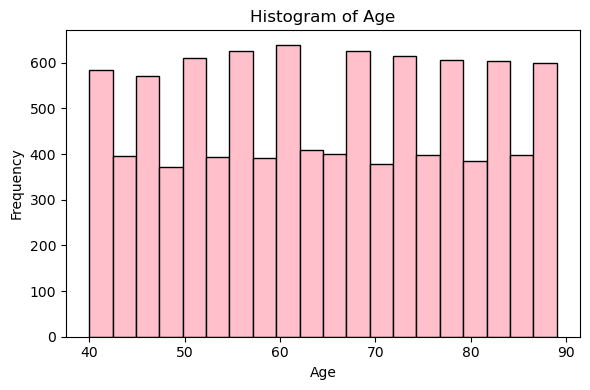

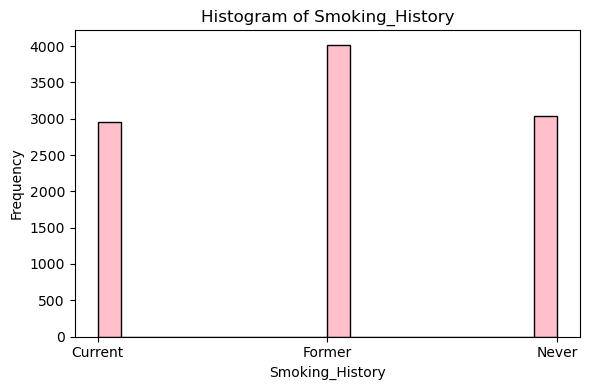

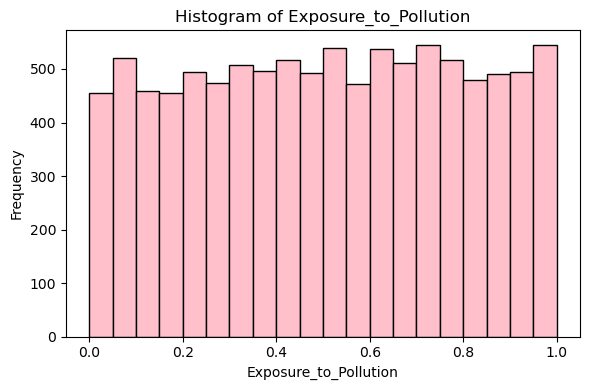

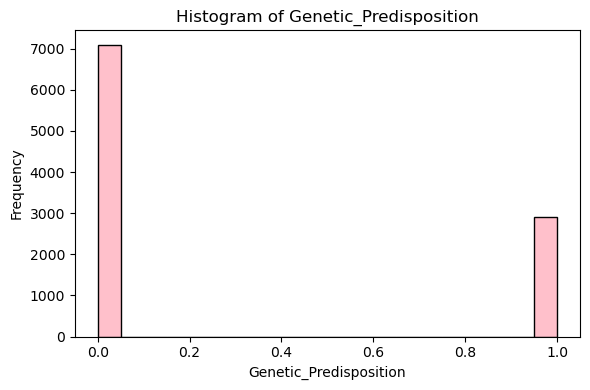

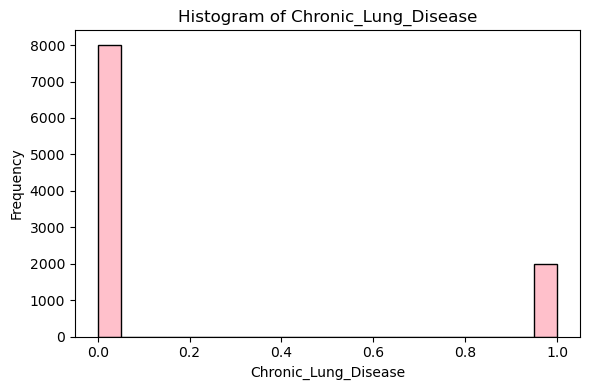

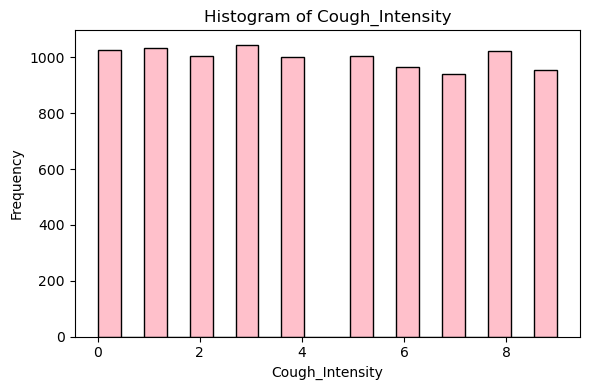

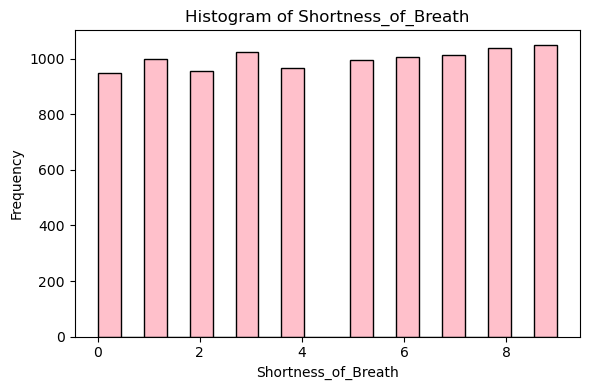

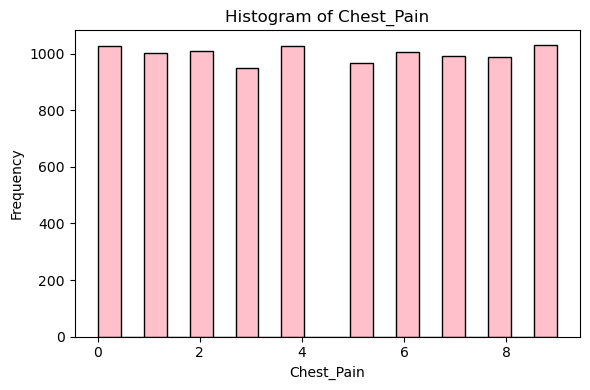

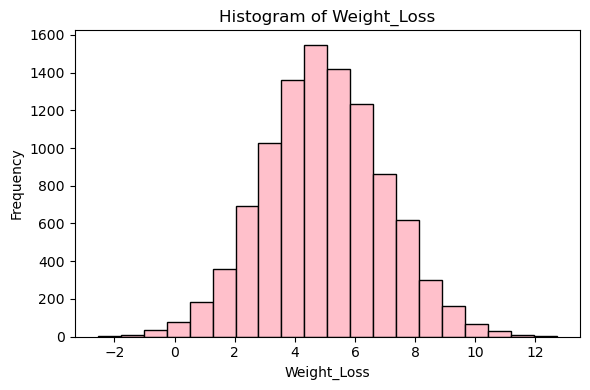

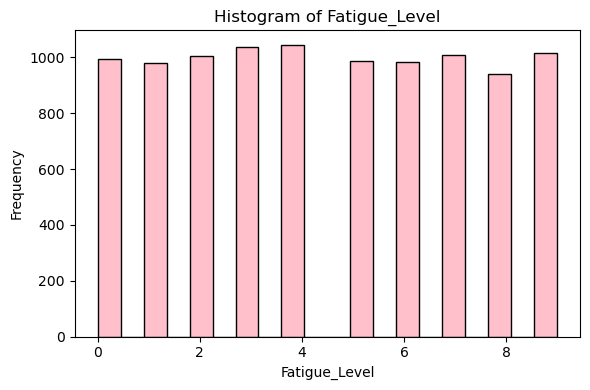

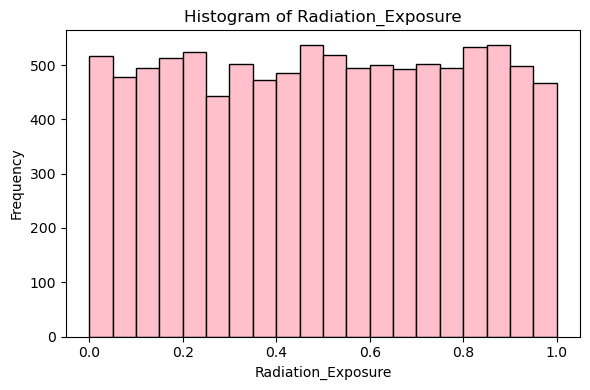

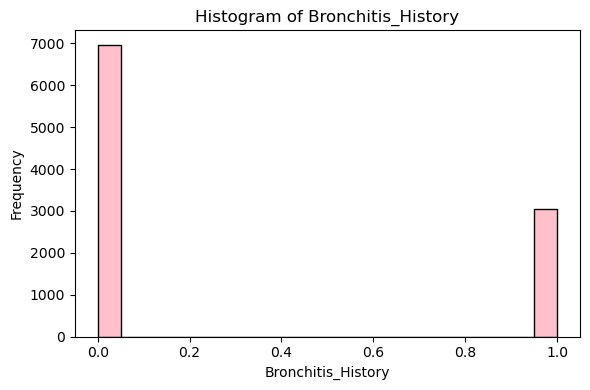

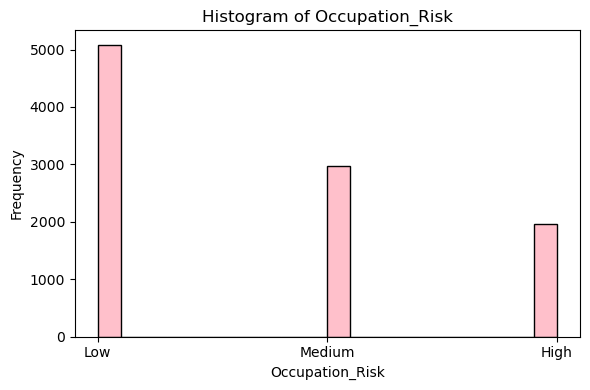

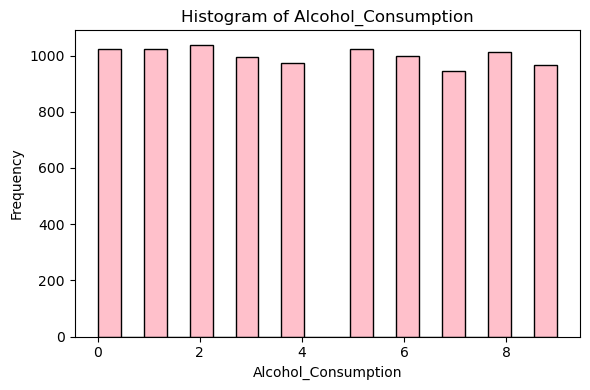

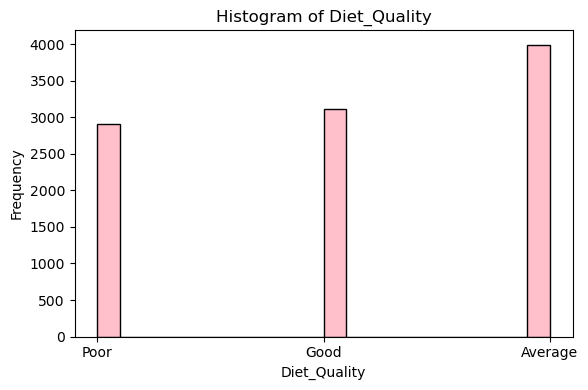

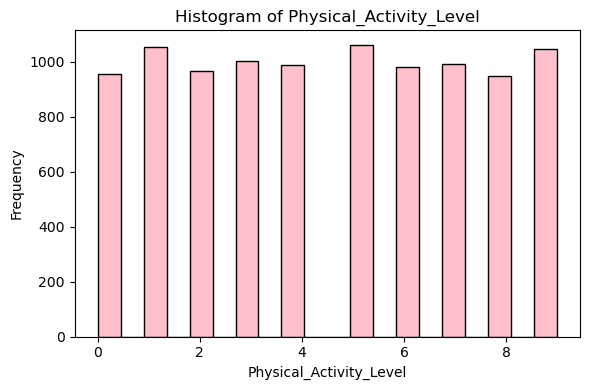

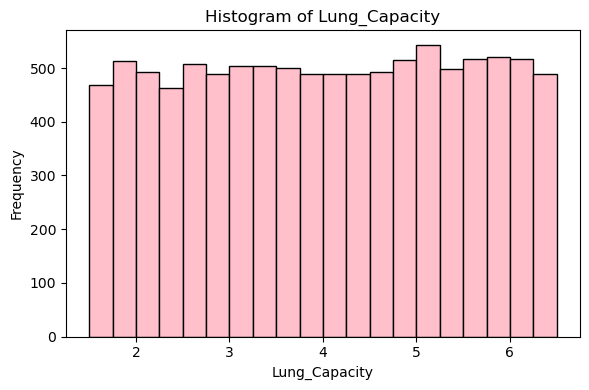

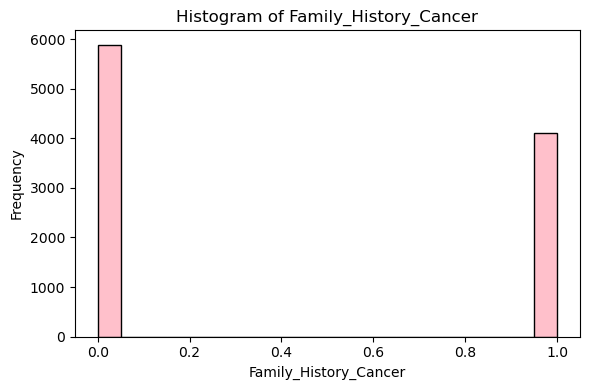

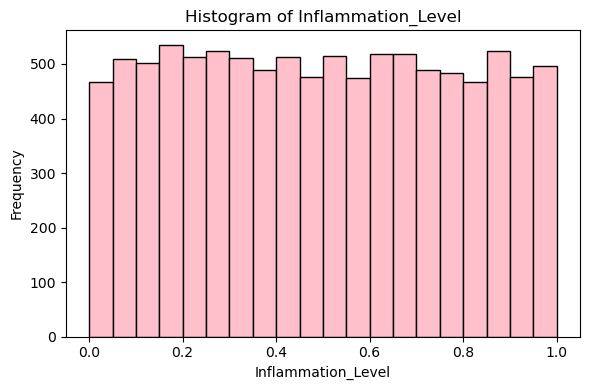

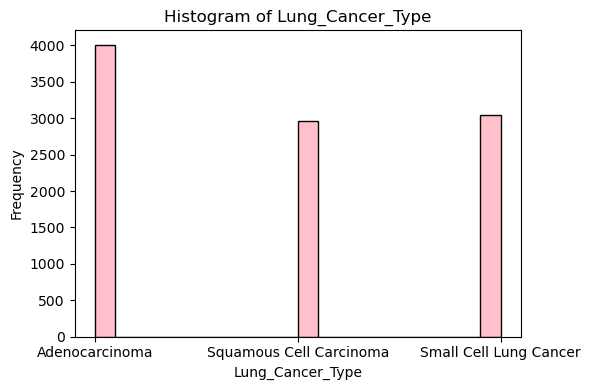

In [ ]:
# remove repetitive columns and make sure header = 0
myData = pd.read_csv("lung_cancer_dataset_large.csv", header=0)
myData = myData.loc[:, ~myData.columns.duplicated()]

features_to_process = [
    'Age',
    'Smoking_History',
    'Exposure_to_Pollution',
    'Genetic_Predisposition',
    'Chronic_Lung_Disease',
    'Cough_Intensity',
    'Shortness_of_Breath',
    'Chest_Pain',
    'Weight_Loss',
    'Fatigue_Level',
    'Radiation_Exposure',
    'Bronchitis_History',
    'Occupation_Risk',
    'Alcohol_Consumption',
    'Diet_Quality',
    'Physical_Activity_Level',
    'Lung_Capacity',
    'Family_History_Cancer',
    'Inflammation_Level',
    'Lung_Cancer_Type'
]

for feat in features_to_process:
    plt.figure(figsize=(6, 4))
    plt.hist(
        myData[feat], 
        bins=20, 
        color='pink', 
        edgecolor='black'
    )
    plt.title(f"Histogram of {feat}")
    plt.xlabel(feat)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

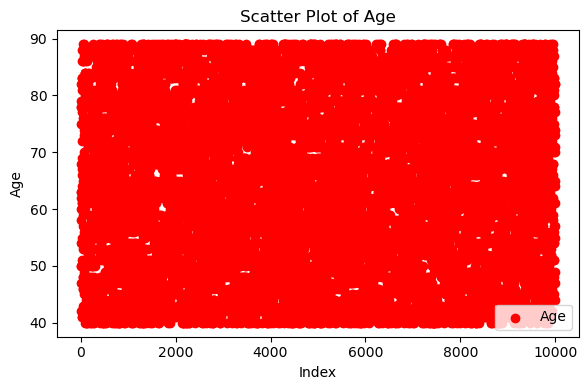

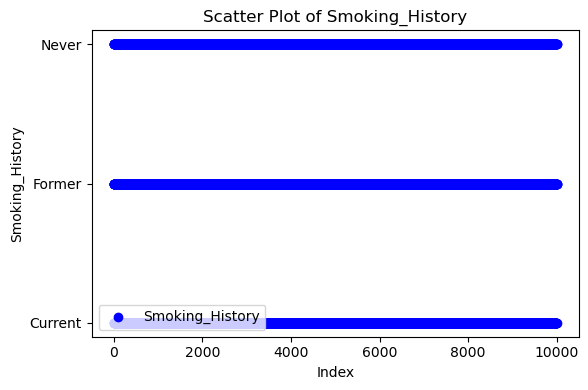

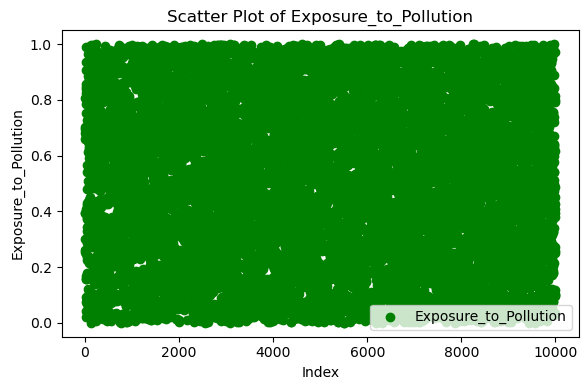

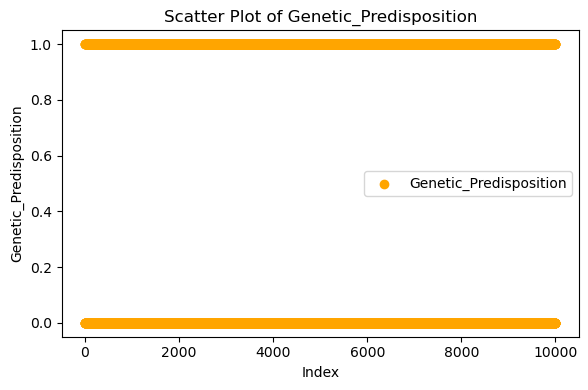

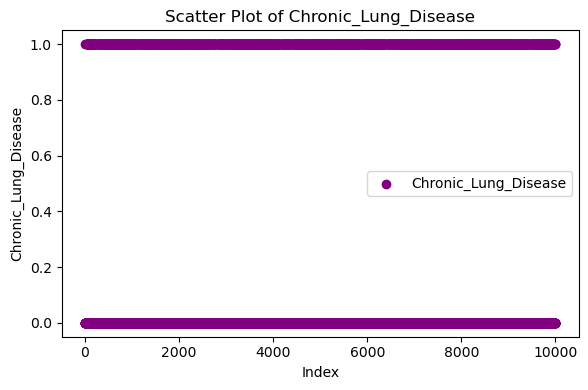

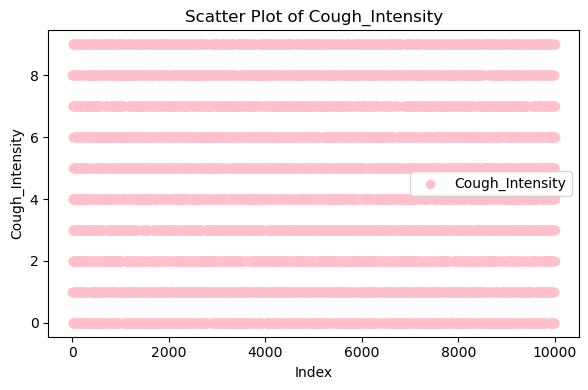

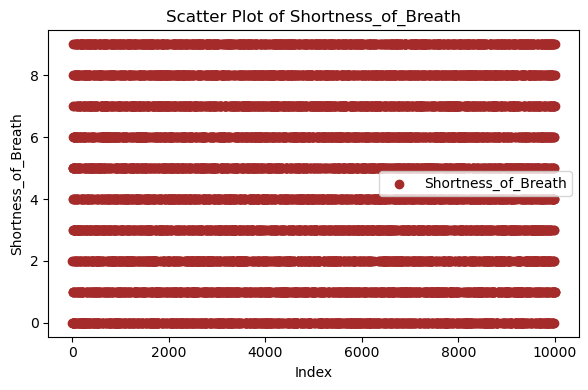

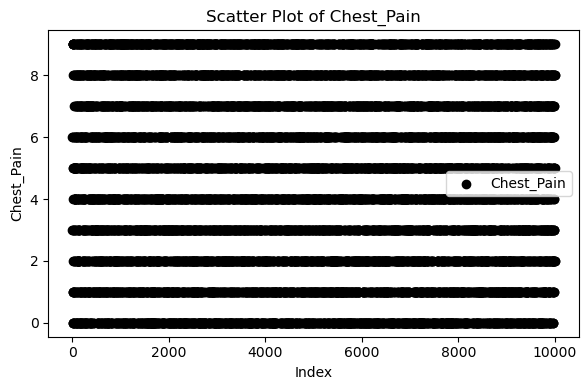

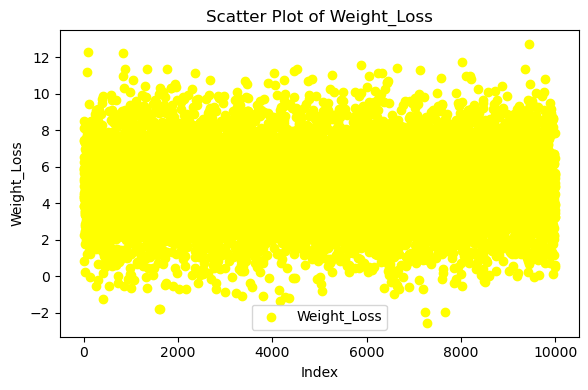

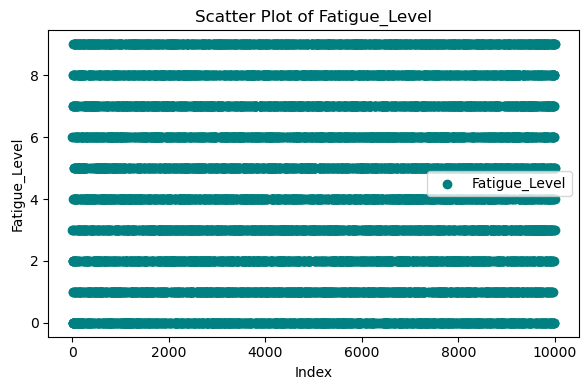

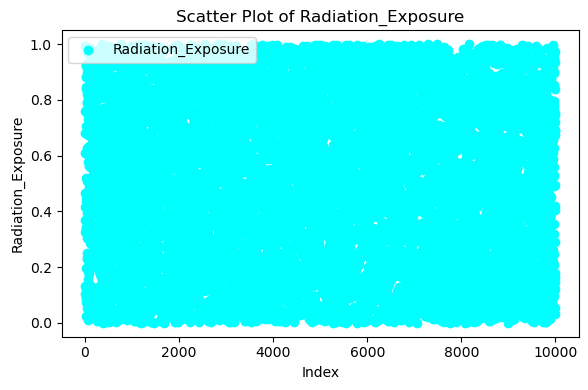

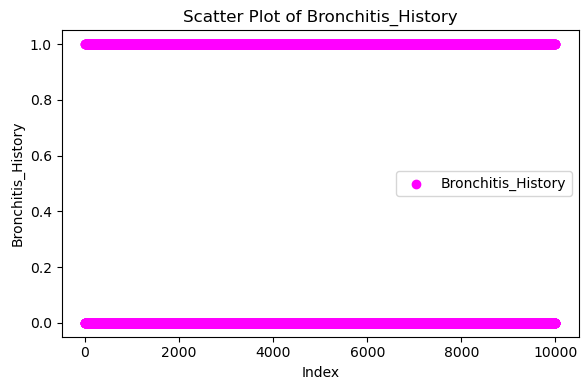

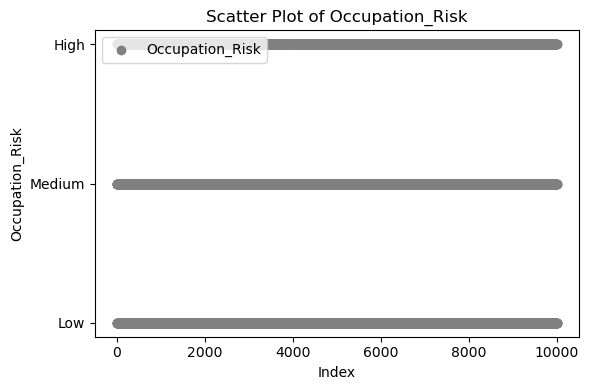

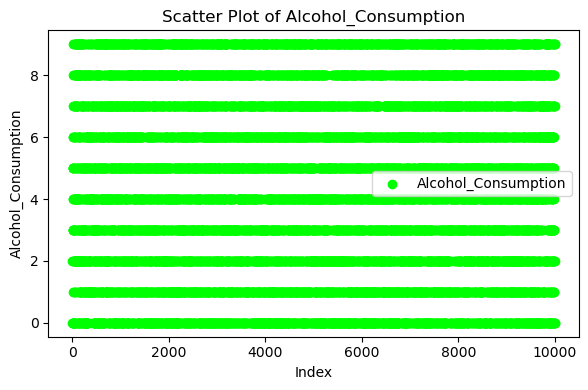

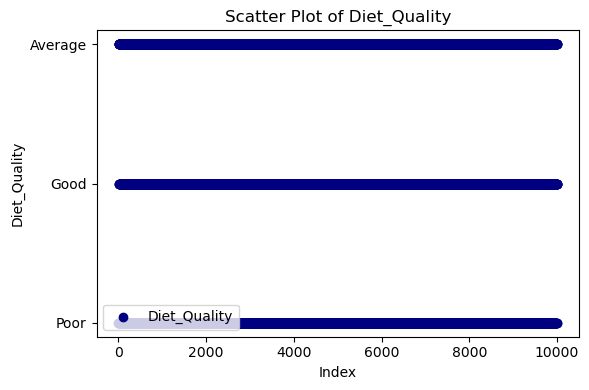

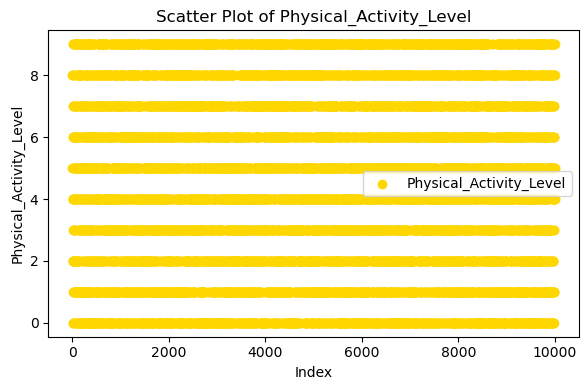

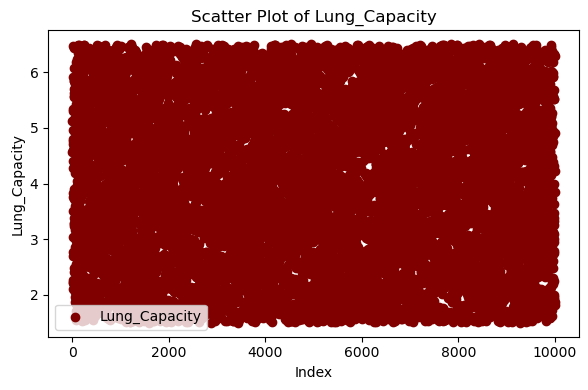

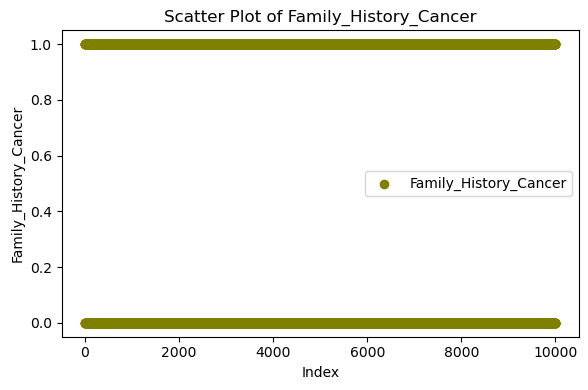

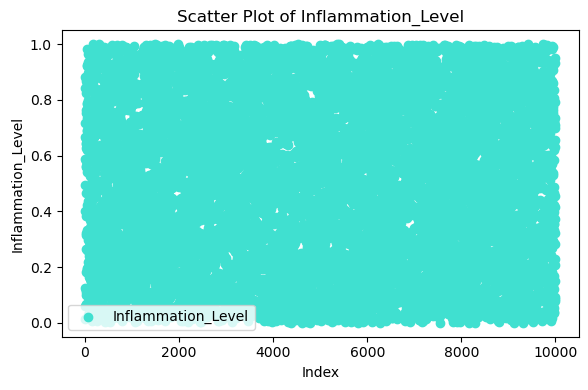

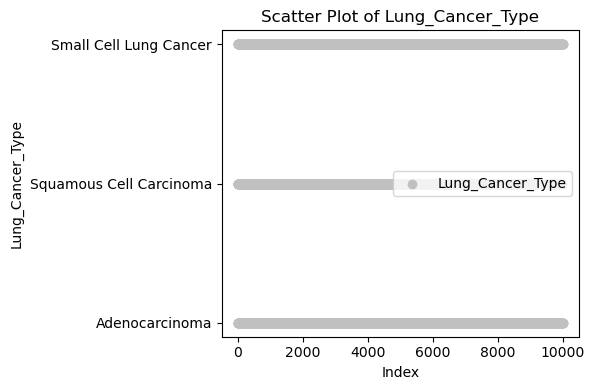

In [ ]:
features_to_process = [
    'Age',
    'Smoking_History',
    'Exposure_to_Pollution',
    'Genetic_Predisposition',
    'Chronic_Lung_Disease',
    'Cough_Intensity',
    'Shortness_of_Breath',
    'Chest_Pain',
    'Weight_Loss',
    'Fatigue_Level',
    'Radiation_Exposure',
    'Bronchitis_History',
    'Occupation_Risk',
    'Alcohol_Consumption',
    'Diet_Quality',
    'Physical_Activity_Level',
    'Lung_Capacity',
    'Family_History_Cancer',
    'Inflammation_Level',
    'Lung_Cancer_Type'
]
features = [
    'Age',
    'Smoking_History',
    'Exposure_to_Pollution',
    'Genetic_Predisposition',
    'Chronic_Lung_Disease',
    'Cough_Intensity',
    'Shortness_of_Breath',
    'Chest_Pain',
    'Weight_Loss',
    'Fatigue_Level',
    'Radiation_Exposure',
    'Bronchitis_History',
    'Occupation_Risk',
    'Alcohol_Consumption',
    'Diet_Quality',
    'Physical_Activity_Level',
    'Lung_Capacity',
    'Family_History_Cancer',
    'Inflammation_Level',
    'Lung_Cancer_Type'
]
colors = [
    "red", "blue", "green", "orange", "purple", "pink", "brown", "black", 
    "yellow", "teal", "cyan", "magenta", "gray", "lime", "navy", "gold", 
    "maroon", "olive", "turquoise", "silver"
]

for i, feat in enumerate(features):
    plt.figure(figsize=(6,4)) 
    plt.scatter(
        x=range(len(myData)),
        y=myData[feat],
        c=colors[i],
        label=feat
    )
    plt.xlabel("Index")     
    plt.ylabel(feat)        
    plt.title(f"Scatter Plot of {feat}")
    plt.legend()
    plt.tight_layout()
    plt.show()

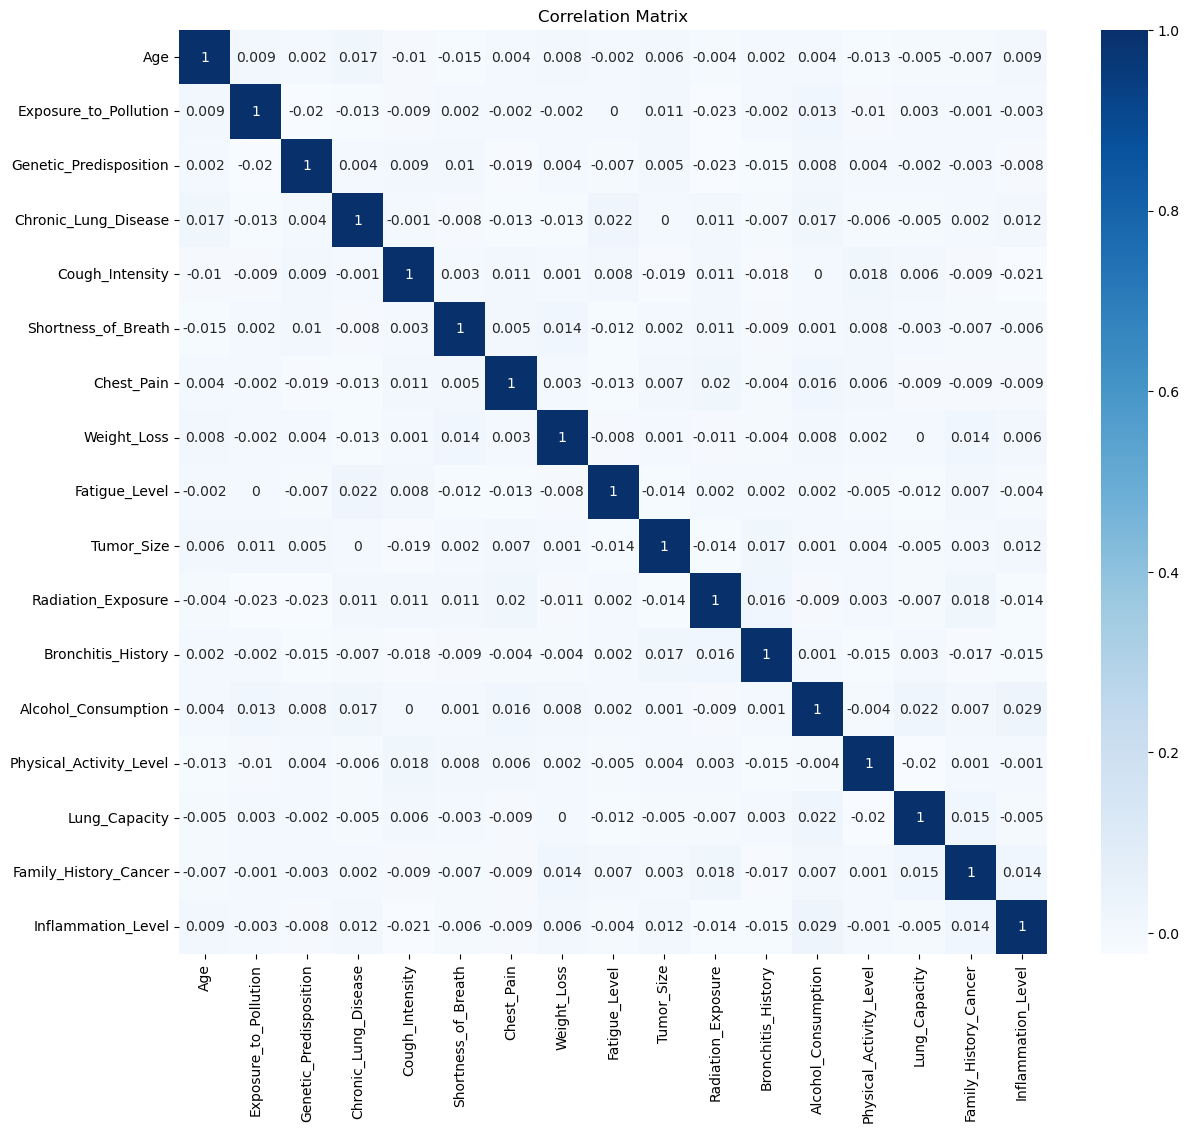

In [ ]:
numeric_cols = myData.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = myData[numeric_cols].corr().round(3)

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap='Blues')
plt.title("Correlation Matrix")
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
features = [
    'Age',
    'Smoking_History',
    'Exposure_to_Pollution',
    'Genetic_Predisposition',
    'Chronic_Lung_Disease',
    'Cough_Intensity',
    'Shortness_of_Breath',
    'Chest_Pain',
    'Weight_Loss',
    'Fatigue_Level',
    'Radiation_Exposure',
    'Bronchitis_History',
    'Occupation_Risk',
    'Alcohol_Consumption',
    'Diet_Quality',
    'Physical_Activity_Level',
    'Lung_Capacity',
    'Family_History_Cancer',
    'Inflammation_Level',
    'Lung_Cancer_Type'
]

#target1: Alcohol_Consumption
target = "Alcohol_Consumption"

for col in features:
    if myData[col].dtype == 'object':
        le = LabelEncoder()
        myData[col] = le.fit_transform(myData[col])

if myData[target].dtype == 'object':
    le_t = LabelEncoder()
    myData[target] = le_t.fit_transform(myData[target])

X = myData[features]
y = myData[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

lr = LogisticRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_lr)*100)

Accuracy: 64.7


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
#KNN
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_knn)*100)

Accuracy: 32.35


In [ ]:
#compare
acc_lr = accuracy_score(y_test, pred_lr)
acc_knn = accuracy_score(y_test, pred_knn)

print("Logistic Regression:", acc_lr*100)
print("KNN:", acc_knn*100)

Logistic Regression: 64.7
KNN: 32.35


In [ ]:
#target2: Smoking_History
target = "Smoking_History"

for col in features:
    if myData[col].dtype == 'object':
        le = LabelEncoder()
        myData[col] = le.fit_transform(myData[col])

if myData[target].dtype == 'object':
    le_t = LabelEncoder()
    myData[target] = le_t.fit_transform(myData[target])

X = myData[features]
y = myData[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

lr = LogisticRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_lr)*100)

Accuracy: 99.95


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
#KNN
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_knn)*100)

Accuracy: 43.45


In [ ]:
#compare
acc_lr = accuracy_score(y_test, pred_lr)
acc_knn = accuracy_score(y_test, pred_knn)

print("Logistic Regression:", acc_lr*100)
print("KNN:", acc_knn*100)

Logistic Regression: 99.95
KNN: 43.45


In [ ]:
#target3: 
target = "Family_History_Cancer"

for col in features:
    if myData[col].dtype == 'object':
        le = LabelEncoder()
        myData[col] = le.fit_transform(myData[col])

if myData[target].dtype == 'object':
    le_t = LabelEncoder()
    myData[target] = le_t.fit_transform(myData[target])

X = myData[features]
y = myData[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

lr = LogisticRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_lr)*100)

Accuracy: 100.0


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
#KNN
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_knn)*100)

Accuracy: 59.199999999999996


In [ ]:
#compare
acc_lr = accuracy_score(y_test, pred_lr)
acc_knn = accuracy_score(y_test, pred_knn)

print("Logistic Regression:", acc_lr*100)
print("KNN:", acc_knn*100)

Logistic Regression: 100.0
KNN: 59.199999999999996
